In [ ]:
from demo_load_datasets_model import *
from demo_helpers import *

In [ ]:
available_models = ['llama-1b','llama-3b','llama-8b','Qwen2_1.5b','Qwen2-0.5B']
MODEL = available_models[1]
model,tokenizer = load_hooked_transformer_model(MODEL)
FIRST_ID_INDEX_LLAMA= 1

device = utils.get_device()
ICL_prompt = False

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded pretrained model meta-llama/Llama-3.2-3B into HookedTransformer
Moving model to device:  cuda


In [4]:
TASK = 'fact_recall'  # or 'fact_recall'
languages =["chinese","japanese","korean","french","spanish","english"]#"chinese",
dataset_list = [
    "object_color","language_family","country_language","country_currency",
    "book_language","person_university","animal_classification",
    "musician_instruments","musician_country","country_religion"
]

In [ ]:


import matplotlib.pyplot as plt
import pandas as pd

def check_correctness(data,LANGUAGE,output_csv,TASK):
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  total_entries = 0
  correct_predictions = 0
  total_attribute_prob = 0.0
  with open(output_csv, mode='w', newline='') as file:
      writer = csv.writer(file)
      writer.writerow(['known_id', 'attribute', 'generated_part', 'is_correct'])
  # Iterate over each entry in the dataset
  for entry in data:
      known_id = entry["known_id"]
      prompt = entry["prompt"]
      attribute = entry["attribute"]
      clean_tokens = model.to_tokens(prompt).to(device)
      attribute_tokens = model.to_tokens(attribute).to(device)
      generated = clean_tokens.clone()  # Start with prompt
      device = model.cfg.device if hasattr(model, "cfg") else "cuda"  # Adjust to your setup
      model.reset_hooks()
      num_attr_tokens = len(tokenizer(attribute, return_tensors='pt')['input_ids'][0])
      MAX_GENERATION_LEN = num_attr_tokens+2
      for i in range(MAX_GENERATION_LEN):  # Generate 10 tokens
        logits, cache = model.run_with_cache(generated, prepend_bos=True)
        next_logits = logits[:, -1, :]  # shape: (batch, vocab)
        next_token_id = next_logits.argmax(dim=-1)  # shape: (batch,)
        next_token = model.tokenizer.decode(next_token_id)
        generated = torch.cat([generated, next_token_id.unsqueeze(1)], dim=1)
      total_output = tokenizer.decode(generated[0], skip_special_tokens=True)
      is_correct, generated_part = is_generation_correct(prompt, total_output, attribute)

      with open(output_csv, mode='a', newline='') as file:
            writer = csv.writer(file)
            writer.writerow([known_id, attribute, generated_part.strip(), is_correct])
      if is_correct:
          correct_predictions += 1
      total_entries+=1
  percentage_correct = (correct_predictions / total_entries) * 100
  return percentage_correct

TASK = 'translation'
from_languages = ['english']
model.reset_hooks()

# Dictionary to store accuracy results
results = {dataset: {lang: 0 for lang in languages} for dataset in dataset_list}

for DATASET in dataset_list:
    for LANGUAGE in languages:
        print(TASK, DATASET, LANGUAGE)
        
        if TASK == 'fact_recall' or TASK =='translate_to_english':
            data = new_load_ROME_data_for_task_dataset_language(TASK, DATASET, LANGUAGE,ICL_prompt=False)
            output_dir = f"knowLLM_model_results/{MODEL}_results/{TASK}/{DATASET}"
            if not os.path.exists(output_dir):
                os.makedirs(output_dir)
            output_csv = os.path.join(output_dir, f"{LANGUAGE}_predictions.csv")
            accuracy = check_correctness(data, LANGUAGE, output_csv, TASK)
            results[DATASET][LANGUAGE] = accuracy  # Store accuracy
        
        elif TASK == 'translation':
            if from_languages is None:
                from_languages = [l for l in languages if l != LANGUAGE]
            
            for FROM_LAN in from_languages:
                data = new_load_ROME_data_for_task_dataset_language(TASK, DATASET, LANGUAGE, FROM_LAN)
                output_dir = f"knowLLM_model_results/{MODEL}_results/{TASK}/{DATASET}/from_{FROM_LAN}"
                if not os.path.exists(output_dir):
                    os.makedirs(output_dir)
                output_csv = os.path.join(output_dir, f"{LANGUAGE}_predictions.csv")
                accuracy = check_correctness(data, LANGUAGE, output_csv, TASK)
                results[DATASET][LANGUAGE] = accuracy  # Store accuracy

        else:
            print("TASK NOT configured")

# Define colors for each language
language_colors = {
    "english": "blue",
    "chinese": "red",
    "japanese": "green",
    "korean": "purple",
    "french": "yellow",
    "spanish": "orange"
}

#TODO chinese, french, japanese, korean, spanish

for DATASET in dataset_list:
    plt.figure(figsize=(10, 6))
    langs = list(results[DATASET].keys())  # Get language names
    accuracies = [x/100 for x in list(results[DATASET].values())]  # Get actual accuracy values
    colors = [language_colors.get(lang, "gray") for lang in langs]  # Default to gray if language missing
    bars = plt.bar(langs, accuracies, color=colors)
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height, f"{height:.2f}", 
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.xlabel("Language")
    plt.ylabel("Correctness")
    plt.title(f"Accuracy by Language for {DATASET}")
    plt.ylim(0, 1)  # Assuming accuracy is between 0 and 1
    plt.xticks(rotation=45)
    
    # Ensure dataset-specific directories exist
    dataset_dir = f"knowLLM_model_results/{MODEL}_results/{TASK}/{DATASET}"
    os.makedirs(dataset_dir, exist_ok=True)
    plot_path = os.path.join(dataset_dir, "accuracy_plot.png")
    plt.savefig(plot_path)
    print(f"Plot saved to {plot_path}")
    plt.close()

translation object_color chinese


In [ ]:
TASK = 'fact_recall'
from_languages = ['english']
model.reset_hooks()

# Dictionary to store accuracy results
results = {dataset: {lang: 0 for lang in languages} for dataset in dataset_list}

for DATASET in dataset_list:
    for LANGUAGE in languages:
        print(TASK, DATASET, LANGUAGE)
        
        if TASK == 'fact_recall' or TASK =='translate_to_english':
            data = new_load_ROME_data_for_task_dataset_language(TASK, DATASET, LANGUAGE,ICL_prompt=False)
            output_dir = f"knowLLM_model_results/{MODEL}_results/{TASK}_ICL/{DATASET}"
            if not os.path.exists(output_dir):
                os.makedirs(output_dir)
            output_csv = os.path.join(output_dir, f"{LANGUAGE}_predictions.csv")
            accuracy = check_correctness(data, LANGUAGE, output_csv, TASK)
            results[DATASET][LANGUAGE] = accuracy  # Store accuracy
        
        elif TASK == 'translation':
            if from_languages is None:
                from_languages = [l for l in languages if l != LANGUAGE]
            
            for FROM_LAN in from_languages:
                data = new_load_ROME_data_for_task_dataset_language(TASK, DATASET, LANGUAGE, FROM_LAN)
                output_dir = f"knowLLM_model_results/{MODEL}_results/{TASK}_ICL/{DATASET}/from_{FROM_LAN}"
                if not os.path.exists(output_dir):
                    os.makedirs(output_dir)
                output_csv = os.path.join(output_dir, f"{LANGUAGE}_predictions.csv")
                accuracy = check_correctness(data, LANGUAGE, output_csv, TASK)
                results[DATASET][LANGUAGE] = accuracy  # Store accuracy

        else:
            print("TASK NOT configured")

# Define colors for each language
language_colors = {
    "english": "blue",
    "chinese": "red",
    "japanese": "green",
    "korean": "purple",
    "french": "yellow",
    "spanish": "orange"
}

#TODO chinese, french, japanese, korean, spanish

for DATASET in dataset_list:
    plt.figure(figsize=(10, 6))
    langs = list(results[DATASET].keys())  # Get language names
    accuracies = [x/100 for x in list(results[DATASET].values())]  # Get actual accuracy values
    colors = [language_colors.get(lang, "gray") for lang in langs]  # Default to gray if language missing
    bars = plt.bar(langs, accuracies, color=colors)
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height, f"{height:.2f}", 
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.xlabel("Language")
    plt.ylabel("Correctness")
    plt.title(f"Accuracy by Language for {DATASET}")
    plt.ylim(0, 1)  # Assuming accuracy is between 0 and 1
    plt.xticks(rotation=45)
    
    # Ensure dataset-specific directories exist
    dataset_dir = f"knowLLM_model_results/{MODEL}_results/{TASK}_ICL/{DATASET}"
    os.makedirs(dataset_dir, exist_ok=True)
    plot_path = os.path.join(dataset_dir, "accuracy_plot.png")
    plt.savefig(plot_path)
    print(f"Plot saved to {plot_path}")
    plt.close()

fact_recall object_color chinese
fact_recall object_color japanese
fact_recall object_color korean
fact_recall object_color french
fact_recall object_color spanish


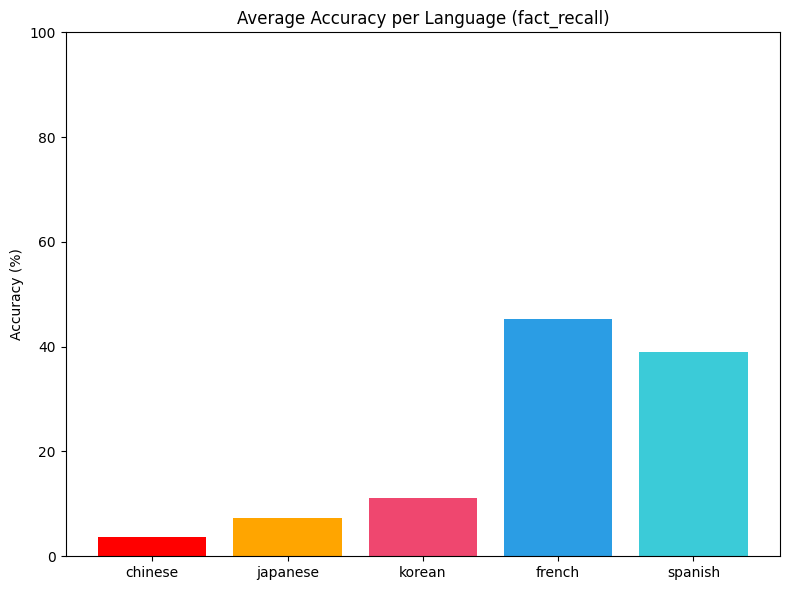

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

languages = ['chinese', 'japanese', 'korean', 'french', 'spanish']
TASK = 'fact_recall'
MODEL = 'llama-3b'  # Update as needed


accuracies = []

for language in languages:
    correct = 0
    total = 0
    for dataset in dataset_list:
        path = f"knowLLM_model_results/{MODEL}_results/{TASK}/{dataset}/{language}_predictions.csv"
        if TASK =='translation':
            path = f"knowLLM_model_results/{MODEL}_results/{TASK}/{dataset}/from_english/{language}_predictions.csv"
        if not os.path.exists(path):
            continue
        df = pd.read_csv(path)
        if 'is_correct' not in df.columns:
            continue
        correct += df['is_correct'].sum()
        total += len(df)
    acc = correct / total * 100 if total > 0 else 0.0
    accuracies.append(acc)

# Plotting
colors = ['#FF0000', '#FFA500', '#EF476F', '#2B9DE4', '#3BCBD8']

plt.figure(figsize=(8, 6))
plt.bar(languages, accuracies, color=colors)
plt.ylabel('Accuracy (%)')
plt.title(f'Average Accuracy per Language ({TASK})')
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(f'knowLLM_PAPER_PLOTS/appendix_{TASK}_general_accuracies.svg')
plt.show()


In [22]:
#LOGIT LENS for each dataset/language/task: fact_recall or explicit translation
#show logit lens diagram for french / japanese 

TASK = 'fact_recall'
layers = range(model.cfg.n_layers)
for DATASET in dataset_list:
    for LANGUAGE in ['french']:
        comparison_languages = [lan for lan in ['english','french','spanish','korean','japanese','chinese'] if lan!=LANGUAGE]
        
        data = new_load_ROME_data_for_task_dataset_language(TASK, DATASET, LANGUAGE, FROM_LAN='english',ICL_prompt=False,ICL_n_shots=None)
        save_top_k_predictions_and_ranks_across_layers(DATASET,data, layers, model, LANGUAGE, comparison_languages, 
                                                       output_dir=None, top_k=1000,MODE='examine_last_tok')

knowLLM_model_results/llama-3b_results/fact_recall/object_color/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/language_family/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/country_language/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/country_currency/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/book_language/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/person_university/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/animal_classification/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/musician_instruments/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/musician_country/topk_preds/examine_last_tok/french
knowLLM_model_results/llama-3b_results/fact_recall/country_religion/top

In [46]:
def agnostic_correct_and_incorrect_list(MODEL, TASK, DATASET, LANGUAGE, EXAMINE_LAYER, MODE='examine_last_tok',
                                        WITH_DIFF_VECTOR=None, WITH_TASK_VECTOR=None,
                                        FIRST_CONVERSION_SUBJECT_TOPK=None, input_directory=None,
                                        specific_known_ids_dict=None):

    if input_directory:
        input_dir = os.path.join(input_directory, f"{DATASET}/attribute_ranks/{MODE}/{LANGUAGE}")
    else:
        if WITH_DIFF_VECTOR is None:
            input_dir = f"knowLLM_model_results/{MODEL}_results/fact_recall/{DATASET}/attribute_ranks/{MODE}/{LANGUAGE}"
        else:
            if WITH_TASK_VECTOR is None:
                input_dir = f"knowLLM_model_results/{MODEL}_results/fact_recall/COMBINED/fact_recall_results_DIFF_LAYER_{WITH_DIFF_VECTOR}/{DATASET}/attribute_ranks/{MODE}/{LANGUAGE}"
            else:
                input_dir = f"knowLLM_model_results/{MODEL}_results/fact_recall/COMBINED/fact_recall_results_DIFF_LAYER_{WITH_DIFF_VECTOR}_and_TASK_vector_LAYER_3/{DATASET}/attribute_ranks/{MODE}/{LANGUAGE}"

    if LANGUAGE == 'english':
        results_csv_fp = os.path.join(input_dir, 'english_rank_prob_results.csv')
    else:
        results_csv_fp = os.path.join(input_dir, 'comparison_english_rank_prob_results.csv')

    if not os.path.exists(results_csv_fp):
        raise FileNotFoundError(f"File not found: {results_csv_fp}")

    df = pd.read_csv(results_csv_fp)

    if specific_known_ids_dict is None:
        filtered_df = df[df['layer'] == EXAMINE_LAYER]
    else:
        filtered_df = df[
            (df['layer'] == EXAMINE_LAYER) &
            (df['known_id'].isin(specific_known_ids_dict[DATASET][LANGUAGE]))
        ]

    if MODE in ['examine_last_tok', 'examine_relation']:
        correct_df = filtered_df[filtered_df['predicted_attribute_rank'] == 0]
    elif MODE == 'examine_subject_tok':
        if FIRST_CONVERSION_SUBJECT_TOPK is None:
            correct_df = filtered_df[filtered_df['predicted_attribute_rank'] == 0]
        else:
            correct_df = filtered_df[
                (filtered_df['predicted_attribute_rank'] > 0) &
                (filtered_df['predicted_attribute_rank'] < FIRST_CONVERSION_SUBJECT_TOPK)
            ]
    else:
        correct_df = pd.DataFrame(columns=filtered_df.columns)  # Empty fallback

    # If MODE is examine_last_tok and language is not English, do additional merging
    if MODE == 'examine_last_tok' and LANGUAGE != 'english':
        alt_fp = os.path.join(input_dir, f'{LANGUAGE}_rank_prob_results.csv')
        if not os.path.exists(alt_fp):
            raise FileNotFoundError(f"File not found: {alt_fp}")
        df_lang = pd.read_csv(alt_fp)
        lang_filtered = df_lang[df_lang['layer'] == EXAMINE_LAYER]
        lang_correct = lang_filtered[lang_filtered['predicted_attribute_rank'] == 0]
        correct_df = pd.concat([correct_df, lang_correct])

    list_of_agnostic_correct = correct_df['known_id'].tolist()
    all_known_ids = filtered_df['known_id'].tolist()
    list_of_agnostic_incorrect = [kid for kid in all_known_ids if kid not in list_of_agnostic_correct]

    return list_of_agnostic_correct, list_of_agnostic_incorrect

In [ ]:
# PLOT logit lens (plotting french here)
#2. Group data and plot logit lens
MODEL = 'llama-3b'
MODE = 'examine_last_tok'
TASK = "fact_recall"
DIFF_LAYER=21
languages_for_eval = ["chinese","french","spanish","japanese","korean","english"]
layers_for_eval = range(28)#[l for l in range(len(model.blocks))]



for LANGUAGE in languages_for_eval:
    final_incorrect_and_agnostic_correct = {}
    final_incorrect_and_agnostic_incorrect = {}

    for DATASET in dataset_list:
        list_of_agnostic_correct, list_of_agnostic_incorrect = agnostic_correct_and_incorrect_list(
            MODEL, TASK, DATASET, LANGUAGE,
            EXAMINE_LAYER=TASK, MODE=MODE,
            WITH_DIFF_VECTOR=None, WITH_TASK_VECTOR=None,
            input_directory=f"knowLLM_model_results/llama-3b_results/{TASK}"
        )
        print(list_of_agnostic_correct)

        list_of_final_correct, list_of_final_incorrect = correct_incorrect_predictions_ids(
                MODEL, DATASET, LANGUAGE, TASK='fact_recall'
            )

        # --- Condition (1): In final_incorrect AND agnostic_correct
        set_intersect_ag_correct = set(list_of_final_incorrect).intersection(set(list_of_agnostic_correct))
        final_incorrect_and_agnostic_correct[DATASET] = list(set_intersect_ag_correct)

        # --- Condition (2): In final_incorrect AND agnostic_incorrect
        set_intersect_ag_incorrect = set(list_of_final_incorrect).intersection(set(list_of_agnostic_incorrect))
        final_incorrect_and_agnostic_incorrect[DATASET] = list(set_intersect_ag_incorrect)

    rank_output_dir = f"knowLLM_model_results/{MODEL}_results/{TASK}"

    # === Plot for final_incorrect ∩ agnostic_correct
    plot_mean_ranking_results(
        MODEL, TASK, LANGUAGE, dataset_list,
        final_incorrect_and_agnostic_correct,
        MODE=MODE,
        rank_output_dir=rank_output_dir,
        plot_title=f"[{LANGUAGE}] Final Incorrect ∩ Agnostic Correct"
    )

    # === Plot for final_incorrect ∩ agnostic_incorrect
    plot_mean_ranking_results(
        MODEL, TASK, LANGUAGE, dataset_list,
        final_incorrect_and_agnostic_incorrect,
        MODE=MODE,
        rank_output_dir=rank_output_dir,
        plot_title=f"[{LANGUAGE}] Final Incorrect ∩ Agnostic Incorrect"
    )


In [55]:
#figure 2


In [61]:
from collections import defaultdict

languages = ['chinese', 'japanese', 'korean', 'french', 'spanish']
MODEL = 'llama-3b'
TASK = 'fact_recall'

for SECOND_CONVERSION_LAYER in [21]:

    totals = defaultdict(int)
    overall_agnostic_correct = 0
    overall_agnostic_incorrect = 0
    overall_total_examples = 0
    
    for DATASET in dataset_list:
        #print(f"\nDataset: {DATASET}")
        for LANGUAGE in languages:
            agnostic_correct, agnostic_incorrect = check_agnostic_correct_from_input_directory(
                MODEL, TASK, DATASET, LANGUAGE,
                EXAMINE_LAYER=SECOND_CONVERSION_LAYER, 
                input_directory = f"knowLLM_model_results/{MODEL}_results/{TASK}/{DATASET}",
                MODE='examine_last_tok',
                WITH_DIFF_VECTOR=None, WITH_TASK_VECTOR=None
            )
            final_correct, final_incorrect = correct_incorrect_predictions_ids(
                MODEL, DATASET, LANGUAGE, TASK='fact_recall'
            )
    
            # Intersections
            fc_agc = len(set(final_correct) & set(agnostic_correct))
            fc_agi = len(set(final_correct) & set(agnostic_incorrect))
            fi_agc = len(set(final_incorrect) & set(agnostic_correct))
            fi_agi = len(set(final_incorrect) & set(agnostic_incorrect))
    
            # Totals per language
            totals['fc_agc'] += fc_agc
            totals['fc_agi'] += fc_agi
            totals['fi_agc'] += fi_agc
            totals['fi_agi'] += fi_agi
            overall_agnostic_correct += len(agnostic_correct)
            overall_agnostic_incorrect += len(agnostic_incorrect)
            overall_total_examples += len(agnostic_correct) + len(agnostic_incorrect)
    
    # === Final Summary ===
    def pct(n): return round(100 * n / overall_total_examples, 2)
    
    print(f"\n====== GLOBAL SUMMARY (Layer {SECOND_CONVERSION_LAYER}) ======")
    print(f"Total evaluated: {overall_total_examples}")
    print(f"Agnostic correct: {overall_agnostic_correct} ({pct(overall_agnostic_correct)}%)")
    print(f"Agnostic incorrect: {overall_agnostic_incorrect} ({pct(overall_agnostic_incorrect)}%)")
    
    print("\nBreakdown of agnostic correct:")
    print(f"  → Final correct:   {totals['fc_agc']} ({pct(totals['fc_agc'])}%)")
    print(f"  → Final incorrect: {totals['fi_agc']} ({pct(totals['fi_agc'])}%)")
    
    print("\nBreakdown of agnostic incorrect:")
    print(f"  → Final correct:   {totals['fc_agi']} ({pct(totals['fc_agi'])}%)")
    print(f"  → Final incorrect: {totals['fi_agi']} ({pct(totals['fi_agi'])}%)")



====== GLOBAL SUMMARY (Layer 21) ======
Total evaluated: 2385
Agnostic correct: 792 (33.21%)
Agnostic incorrect: 1593 (66.79%)

Breakdown of agnostic correct:
  → Final correct:   385 (16.14%)
  → Final incorrect: 407 (17.06%)

Breakdown of agnostic incorrect:
  → Final correct:   123 (5.16%)
  → Final incorrect: 1470 (61.64%)


In [ ]:
#Section 3: Translation Vector Effect
#extraction: demo_extract_vectors.ipynb
#here's the evaluation data 

In [ ]:
#figure 3 (a) Neuron cosine similarity

In [91]:
import torch
import torch.nn.functional as F
from functools import partial

component = 'hook_post'  # or 'resid_pre'
split_sizes = (0.4, 0.1, 0.5)
split_sizes_str = '_'.join(str(s) for s in split_sizes)
DIFF_LAYER = 21
EXAMINE_LAYERS = range(DIFF_LAYER,model.cfg.n_layers)
H_VECTOR_LAYER_LIST = [0]
H_VECTOR_SCALE_LIST = [0]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
diff_vector_path = None #
for split_strategy in ['within_dataset']:
    for RANDOM_SEED in [15]:
        if split_strategy == 'within_dataset':
            train_ids_dict, val_ids_dict, test_ids_dict = get_train_val_test_within_dataset_split(
                dataset_list=dataset_list,
                languages=languages,
                task_for_splitting="fact_recall",
                split_sizes=split_sizes,
                random_state=RANDOM_SEED
            )
        # === Store results per language and per layer
        cos_similarity_by_language = defaultdict(lambda: defaultdict(list))
        for LANGUAGE in languages:
            cos_similarity_dict={}
            for l in EXAMINE_LAYERS:
                cos_similarity_dict[l] =[]
            for DATASET in dataset_list:
                test_known_ids = test_ids_dict[DATASET][LANGUAGE]
                agnostic_input_directory =  f"knowLLM_model_results/llama-3b_results/{TASK}/{DATASET}"
                agnostic_correct_known_ids, _ = check_agnostic_correct_from_input_directory(
                    MODEL, TASK, DATASET, LANGUAGE,
                    EXAMINE_LAYER=DIFF_LAYER,
                    input_directory=agnostic_input_directory,
                    MODE='examine_last_tok',
                    WITH_DIFF_VECTOR=None, WITH_TASK_VECTOR=None)
                agnostic_correct_test_ids = set(agnostic_correct_known_ids) & set(test_known_ids)

                fact_data = new_load_ROME_data_for_task_dataset_language('fact_recall', DATASET, LANGUAGE, FROM_LAN='english')
                translation_data = new_load_ROME_data_for_task_dataset_language('translation', DATASET, LANGUAGE, FROM_LAN='english')

                for entry in fact_data:
                    known_id = entry["known_id"]
                    if known_id not in agnostic_correct_test_ids:
                        continue

                    prompt = entry["prompt"]
                    subject = entry["subject"]

                    clean_tokens = model.to_tokens(prompt).to(device)
                    translation_entry = next((e for e in translation_data if e["known_id"] == known_id), None)
                    if translation_entry is None:
                        continue
                    translation_prompt = translation_entry["prompt"]
                    translation_tokens = model.to_tokens(translation_prompt).to(device)

                    with torch.no_grad():
                        model.reset_hooks()

                        # Optional: inject difference vector
                        if diff_vector_path is not None:
                            difference_vector = torch.load(diff_vector_path, map_location=device)
                            model.add_hook(
                                lambda name: name == utils.get_act_name('resid_pre', DIFF_LAYER),
                                partial(embedding_add_difference_vector, pos=-1, difference_vector=difference_vector),
                                level=1
                            )

                        _, fact_cache = model.run_with_cache(clean_tokens)
                        _, translation_cache = model.run_with_cache(translation_tokens)

                        
                        for LAYER in EXAMINE_LAYERS:
                            if component == 'hook_post':
                                filter_name = f'blocks.{LAYER}.mlp.hook_post'
                            elif component == 'resid_pre':
                                filter_name = utils.get_act_name('resid_pre', LAYER)
                            orig_act = fact_cache[filter_name][0, -1, :]
                            trans_act = translation_cache[filter_name][0, -1, :]
                            sim = F.cosine_similarity(orig_act, trans_act, dim=0).item()
     
                            cos_similarity_dict[LAYER].append(sim)
                        #print(cos_similarity_dict[LAYER])

            # === After the data collection loop, print average per layer ===
            print(f"\n[{split_strategy}] Cosine Similarity Summary for Language: {LANGUAGE}")
            for layer, sim_list in sorted(cos_similarity_dict.items()):
                if sim_list:
                    avg_sim = sum(sim_list) / len(sim_list)
                    cos_similarity_by_language[LANGUAGE][layer] = avg_sim
                    
                    print(f"  → Layer {layer}: Avg Cosine Similarity = {avg_sim:.4f} (n={len(sim_list)})")
                else:
                    print(f"  → Layer {layer}: No data")
            print(cos_similarity_by_language[LANGUAGE])



[within_dataset] Cosine Similarity Summary for Language: chinese
  → Layer 21: Avg Cosine Similarity = 0.5036 (n=50)
  → Layer 22: Avg Cosine Similarity = 0.5410 (n=50)
  → Layer 23: Avg Cosine Similarity = 0.4813 (n=50)
  → Layer 24: Avg Cosine Similarity = 0.5449 (n=50)
  → Layer 25: Avg Cosine Similarity = 0.5695 (n=50)
  → Layer 26: Avg Cosine Similarity = 0.4864 (n=50)
  → Layer 27: Avg Cosine Similarity = 0.6172 (n=50)
defaultdict(<class 'list'>, {21: 0.5035812503099442, 22: 0.5409822458028793, 23: 0.4812872621417046, 24: 0.5448739165067673, 25: 0.569548306465149, 26: 0.4864319407939911, 27: 0.6171981549263})

[within_dataset] Cosine Similarity Summary for Language: japanese
  → Layer 21: Avg Cosine Similarity = 0.4290 (n=34)
  → Layer 22: Avg Cosine Similarity = 0.4137 (n=34)
  → Layer 23: Avg Cosine Similarity = 0.3882 (n=34)
  → Layer 24: Avg Cosine Similarity = 0.4521 (n=34)
  → Layer 25: Avg Cosine Similarity = 0.5107 (n=34)
  → Layer 26: Avg Cosine Similarity = 0.4714 (n=3

In [92]:
import torch
import torch.nn.functional as F
from functools import partial

component = 'hook_post'  # or 'resid_pre'
split_sizes = (0.4, 0.1, 0.5)
split_sizes_str = '_'.join(str(s) for s in split_sizes)
DIFF_LAYER = 21
EXAMINE_LAYERS = range(DIFF_LAYER,model.cfg.n_layers)
H_VECTOR_LAYER_LIST = [0]
H_VECTOR_SCALE_LIST = [0]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
diff_vector_path = 'knowLLM_model_results/llama-3b_results/fact_recall/EVALUATION_0.4_0.1_0.5/within_dataset/seed_15/diff_layer_21_task_0_0/difference_vector_21.pt'
for split_strategy in ['within_dataset']:
    for RANDOM_SEED in [15]:
        if split_strategy == 'within_dataset':
            train_ids_dict, val_ids_dict, test_ids_dict = get_train_val_test_within_dataset_split(
                dataset_list=dataset_list,
                languages=languages,
                task_for_splitting="fact_recall",
                split_sizes=split_sizes,
                random_state=RANDOM_SEED
            )
        cos_similarity_by_language_INTERVENTION= defaultdict(lambda: defaultdict(list))
        for LANGUAGE in languages:
            cos_similarity_dict={}
            for l in EXAMINE_LAYERS:
                cos_similarity_dict[l] =[]
            for DATASET in dataset_list:
                test_known_ids = test_ids_dict[DATASET][LANGUAGE]
                agnostic_input_directory =  f"knowLLM_model_results/llama-3b_results/{TASK}/{DATASET}"
                agnostic_correct_known_ids, _ = check_agnostic_correct_from_input_directory(
                    MODEL, TASK, DATASET, LANGUAGE,
                    EXAMINE_LAYER=DIFF_LAYER,
                    input_directory=agnostic_input_directory,
                    MODE='examine_last_tok',
                    WITH_DIFF_VECTOR=None, WITH_TASK_VECTOR=None
                )

                # Restrict to IDs that are both test IDs and agnostic correct
                agnostic_correct_test_ids = set(agnostic_correct_known_ids) & set(test_known_ids)

                fact_data = new_load_ROME_data_for_task_dataset_language('fact_recall', DATASET, LANGUAGE, FROM_LAN='english')
                translation_data = new_load_ROME_data_for_task_dataset_language('translation', DATASET, LANGUAGE, FROM_LAN='english')

                for entry in fact_data:
                    known_id = entry["known_id"]
                    if known_id not in agnostic_correct_test_ids:
                        continue

                    prompt = entry["prompt"]
                    subject = entry["subject"]

                    clean_tokens = model.to_tokens(prompt).to(device)
                    translation_entry = next((e for e in translation_data if e["known_id"] == known_id), None)
                    if translation_entry is None:
                        continue
                    translation_prompt = translation_entry["prompt"]
                    translation_tokens = model.to_tokens(translation_prompt).to(device)

                    with torch.no_grad():
                        model.reset_hooks()

                        # Optional: inject difference vector
                        if diff_vector_path is not None:
                            difference_vector = torch.load(diff_vector_path, map_location=device)
                            model.add_hook(
                                lambda name: name == utils.get_act_name('resid_pre', DIFF_LAYER),
                                partial(embedding_add_difference_vector, pos=-1, difference_vector=difference_vector),
                                level=1
                            )

                        _, fact_cache = model.run_with_cache(clean_tokens)
                        _, translation_cache = model.run_with_cache(translation_tokens)

                        
                        for LAYER in EXAMINE_LAYERS:
                            if component == 'hook_post':
                                filter_name = f'blocks.{LAYER}.mlp.hook_post'
                            elif component == 'resid_pre':
                                filter_name = utils.get_act_name('resid_pre', LAYER)
                            orig_act = fact_cache[filter_name][0, -1, :]
                            trans_act = translation_cache[filter_name][0, -1, :]
                            sim = F.cosine_similarity(orig_act, trans_act, dim=0).item()
     
                            cos_similarity_dict[LAYER].append(sim)
                        #print(cos_similarity_dict[LAYER])

            # === After the data collection loop, print average per layer ===
            print(f"\n[{split_strategy}] Cosine Similarity Summary for Language: {LANGUAGE}")
            for layer, sim_list in sorted(cos_similarity_dict.items()):
                if sim_list:
                    avg_sim = sum(sim_list) / len(sim_list)
                    cos_similarity_by_language_INTERVENTION[LANGUAGE][layer] = avg_sim
                    print(f"  → Layer {layer}: Avg Cosine Similarity = {avg_sim:.4f} (n={len(sim_list)})")
                else:
                    print(f"  → Layer {layer}: No data")
        #TODO: i want to collect the final results stored in a dict for each language so i coudl use for plotting later



[within_dataset] Cosine Similarity Summary for Language: chinese
  → Layer 21: Avg Cosine Similarity = 0.6429 (n=50)
  → Layer 22: Avg Cosine Similarity = 0.6784 (n=50)
  → Layer 23: Avg Cosine Similarity = 0.6327 (n=50)
  → Layer 24: Avg Cosine Similarity = 0.6650 (n=50)
  → Layer 25: Avg Cosine Similarity = 0.7092 (n=50)
  → Layer 26: Avg Cosine Similarity = 0.6476 (n=50)
  → Layer 27: Avg Cosine Similarity = 0.7636 (n=50)

[within_dataset] Cosine Similarity Summary for Language: japanese
  → Layer 21: Avg Cosine Similarity = 0.5900 (n=34)
  → Layer 22: Avg Cosine Similarity = 0.5808 (n=34)
  → Layer 23: Avg Cosine Similarity = 0.5747 (n=34)
  → Layer 24: Avg Cosine Similarity = 0.5989 (n=34)
  → Layer 25: Avg Cosine Similarity = 0.6727 (n=34)
  → Layer 26: Avg Cosine Similarity = 0.6664 (n=34)
  → Layer 27: Avg Cosine Similarity = 0.7627 (n=34)

[within_dataset] Cosine Similarity Summary for Language: korean
  → Layer 21: Avg Cosine Similarity = 0.6179 (n=49)
  → Layer 22: Avg Cosi

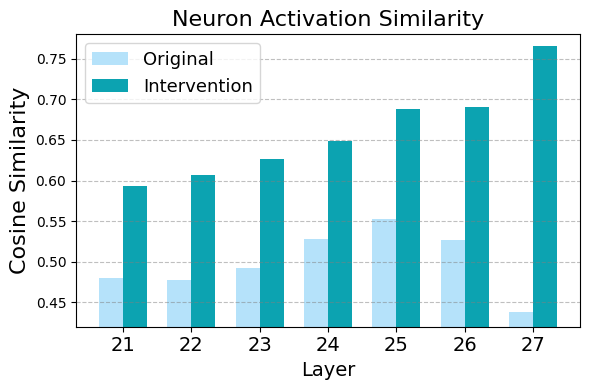

In [109]:

plot_bar_plot_fact_translate_similarity_across_layers(
     cos_similarity_by_language,
     cos_similarity_by_language_INTERVENTION,
     DIFF_LAYER=21,
     model=model)


In [129]:
from collections import defaultdict
import csv, os

#print out a given directory's results
MODEL = 'llama-3b'
langs = ['chinese', 'japanese','korean','french','spanish','english']#, 'spanish','english']
base = f"knowLLM_model_results/{MODEL}_results/fact_recall/"

TASK = 'fact_recall'
layers_for_eval = range(28)

# Get original results
test_dir_orig = f'EVALUATION_0.4_0.1_0.5/within_dataset/seed_15/orig/test/'

DIFF_LAYER = 21
test_dir_interv = f'EVALUATION_0.4_0.1_0.5/within_dataset/seed_15/diff_layer_{DIFF_LAYER}_task_0_0/test/'


for test_dir in [test_dir_orig,test_dir_interv]:
    print(DIFF_LAYER,H_VECTOR_LAYER,H_VECTOR_SCALE)
    directory = os.path.join(base, test_dir)
    results = aggregate_results_for_certain_dir(directory,langs)
    print_results_table(results,langs)



21 0 0

📊 Performance Summary:

Lang       |  Total |   Acc% |   Agn% |   Rel% |  TransAcc% |   ExplTransAcc%
---------------------------------------------------------------------------
chinese    |    251 |   2.39 |  17.93 |  17.93 |       0.00 |           64.44
japanese   |    248 |   6.45 |  11.69 |  23.79 |      34.48 |           75.86
korean     |    248 |  10.48 |  18.95 |  27.02 |      40.43 |           65.96
french     |    250 |  46.40 |  53.60 |  28.80 |      72.39 |           82.09
spanish    |    224 |  36.16 |  45.98 |  28.57 |      50.49 |           85.44
english    |    248 |  61.29 |  56.05 |  26.61 |      81.29 |           84.17
---------------------------------------------------------------------------
non-eng    |   1221 | 20.0655200655 |  29.32 |  25.14 |      49.45 |           74.76
21 0 0

📊 Performance Summary:

Lang       |  Total |   Acc% |   Agn% |   Rel% |  TransAcc% |   ExplTransAcc%
---------------------------------------------------------------------------

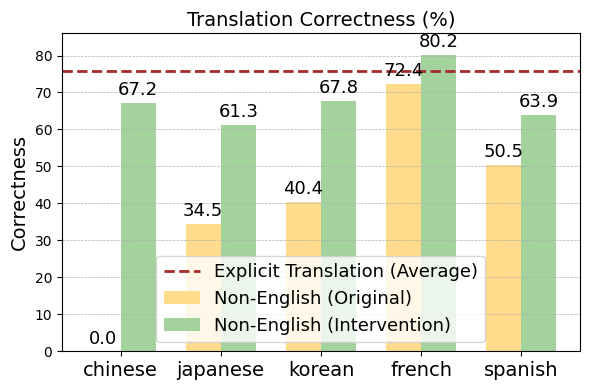

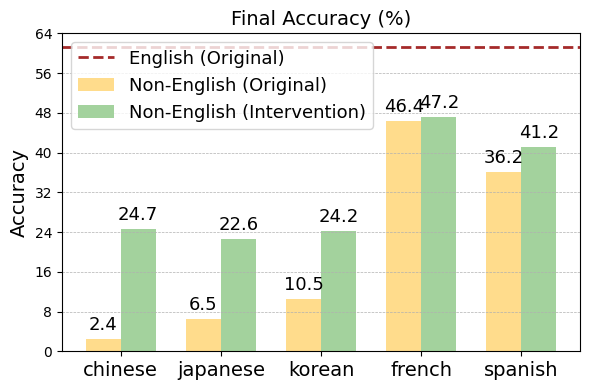

In [37]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Helper function to extract necessary info for plotting
def extract_plot_data(orig_results, intervention_results, languages):
    # Data containers
    non_eng_translation_orig = []
    non_eng_translation_interv = []
    non_eng_explicit_translation_orig = []
    non_eng_explicit_translation_interv = []
    non_eng_final_acc_orig = []
    non_eng_final_acc_interv = []
    english_final_acc_orig = None
    
    # Language labels for non-English
    non_eng_langs = []

    # For each language, extract translation accuracy and final accuracy
    for lang in languages:
        if lang == 'english':
            # For English, we only need the final accuracy as baseline
            orig_rec = orig_results['check'].get(lang, {})
            orig_total = orig_rec.get('total', 0)
            orig_correct = orig_rec.get('correct', 0)
            english_final_acc_orig = (orig_correct / orig_total * 100) if orig_total > 0 else 0
            continue
            
        # For non-English languages
        non_eng_langs.append(lang)
        orig_rec = orig_results['check'].get(lang, {})
        interv_rec = intervention_results['check'].get(lang, {})

        # Translation accuracy (translation_acc)
        orig_trans_acc = orig_rec.get('translation_acc', 0.0) * 100
        interv_trans_acc = interv_rec.get('translation_acc', 0.0) * 100
        
        # Explicit translation accuracy
        orig_explicit_trans_acc = orig_rec.get('explicit_translation_acc', 0.0) * 100
        interv_explicit_trans_acc = interv_rec.get('explicit_translation_acc', 0.0) * 100

        # Final accuracy (acc%) = correct / total * 100
        orig_total = orig_rec.get('total', 0)
        orig_correct = orig_rec.get('correct', 0)
        orig_acc = (orig_correct / orig_total * 100) if orig_total > 0 else 0

        interv_total = interv_rec.get('total', 0)
        interv_correct = interv_rec.get('correct', 0)
        interv_acc = (interv_correct / interv_total * 100) if interv_total > 0 else 0

        # Append to our data containers
        non_eng_translation_orig.append(orig_trans_acc)
        non_eng_translation_interv.append(interv_trans_acc)
        non_eng_explicit_translation_orig.append(orig_explicit_trans_acc)
        non_eng_explicit_translation_interv.append(interv_explicit_trans_acc)
        non_eng_final_acc_orig.append(orig_acc)
        non_eng_final_acc_interv.append(interv_acc)

    return {
        'non_eng_langs': non_eng_langs,
        'non_eng_translation_orig': non_eng_translation_orig,
        'non_eng_translation_interv': non_eng_translation_interv,
        'non_eng_explicit_translation_orig': non_eng_explicit_translation_orig,
        'non_eng_explicit_translation_interv': non_eng_explicit_translation_interv,
        'non_eng_final_acc_orig': non_eng_final_acc_orig,
        'non_eng_final_acc_interv': non_eng_final_acc_interv,
        'english_final_acc_orig': english_final_acc_orig
    }

def plot_translation_correctness(data):
    """Plot the translation correctness comparison"""
    # Extract data
    langs = data['non_eng_langs']
    translation_orig = data['non_eng_translation_orig']
    translation_interv = data['non_eng_translation_interv']
    
    # Colors for the two bars
    colors = ['#FFDC8C', '#A3D29D']
    conditions = ['Original', 'Intervention']
    
    # Plot setup
    fig, ax = plt.subplots(figsize=(6,4))
    bar_width = 0.35
    index = np.arange(len(langs))
    
    # Plot each condition
    bars1 = ax.bar(index, translation_orig, bar_width, label='Non-English (Original)', color=colors[0])
    bars2 = ax.bar(index + bar_width, translation_interv, bar_width, label='Non-English (Intervention)', color=colors[1])
    
    # Add value labels above bars
    for i in range(len(langs)):
        ax.text(i, translation_orig[i] + 1, f'{translation_orig[i]:.1f}', ha='center', va='bottom', fontsize=13)
        ax.text(i + bar_width, translation_interv[i] + 1, f'{translation_interv[i]:.1f}', ha='center', va='bottom', fontsize=13)
    
    # Configure axes and legend
    
    ax.set_ylabel('Correctness',fontsize=14)
    ax.set_title('Translation Correctness (%)',fontsize=14)
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(langs,fontsize=14)
    ax.set_ylim(0, 86)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.axhline(y=75.86, color='brown', linestyle='--', linewidth=2, label='Explicit Translation (Average)')
    ax.legend(fontsize=13)
    ax.grid(True, axis='y', linestyle='--', linewidth=0.5)
    
    plt.tight_layout()
    plt.savefig("knowLLM_PAPER_PLOTS/translation_correctness_comparison.svg")
    plt.show()

def plot_final_accuracy(data):
    """Plot the final accuracy comparison with English baseline"""
    # Extract data
    langs = data['non_eng_langs']
    final_acc_orig = data['non_eng_final_acc_orig']
    final_acc_interv = data['non_eng_final_acc_interv']
    english_final_acc = data['english_final_acc_orig']
    
    # Colors for the two bars
    colors = ['#FFDC8C', '#A3D29D']
    conditions = ['Original', 'Intervention']
    
    # Plot setup
    fig, ax = plt.subplots(figsize=(6,4))
    bar_width = 0.35
    index = np.arange(len(langs))
    
    # Plot each condition
    bars1 = ax.bar(index, final_acc_orig, bar_width, label='Non-English (Original)', color=colors[0])
    bars2 = ax.bar(index + bar_width, final_acc_interv, bar_width, label='Non-English (Intervention)', color=colors[1])
    
    # Add value labels above bars
    for i in range(len(langs)):
        ax.text(i, final_acc_orig[i] + 1, f'{final_acc_orig[i]:.1f}', ha='center', va='bottom', fontsize=13)
        ax.text(i + bar_width, final_acc_interv[i] + 1, f'{final_acc_interv[i]:.1f}', ha='center', va='bottom', fontsize=13)
    
    # Add horizontal line for English original final accuracy
    ax.axhline(y=61.29, color='brown', linestyle='--', linewidth=2, label='English (Original)')
    
    # Configure axes and legend
    
    ax.set_ylabel('Accuracy',fontsize=14)
    ax.set_title('Final Accuracy (%)',fontsize=14)
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(langs,fontsize=14)
    ax.set_ylim(0, 64)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=13
             )
    ax.grid(True, axis='y', linestyle='--', linewidth=0.5)
    
    plt.tight_layout()
    plt.savefig("knowLLM_PAPER_PLOTS/translation_final_accuracy_comparison.svg")
    plt.show()


MODEL = 'llama-3b'
langs = ['chinese', 'japanese', 'korean', 'french', 'spanish', 'english']
base = f"knowLLM_model_results/{MODEL}_results/fact_recall/"


layers_for_eval = range(model.cfg.n_layers)

# Get original results
test_dir_orig = f'EVALUATION_0.4_0.1_0.5/within_dataset/seed_15/orig/test/'
directory_orig = os.path.join(base, test_dir_orig)
orig_results = aggregate_results_for_certain_dir(directory_orig, langs)

# Get intervention results
DIFF_LAYER = 21
test_dir_interv = f'EVALUATION_0.4_0.1_0.5/within_dataset/seed_15/diff_layer_{DIFF_LAYER}_task_0_0/test/'
directory_interv = os.path.join(base, test_dir_interv)
intervention_results = aggregate_results_for_certain_dir(directory_interv, langs)

# Extract data for plotting
plot_data = extract_plot_data(orig_results, intervention_results, langs)

# Create plots
plot_translation_correctness(plot_data)
plot_final_accuracy(plot_data)
